# Iris Flower Classification Using Machine Learning

## Objective
The objective of this project is to build and evaluate machine learning classification models that predict the species of an iris flower using four physical measurements: sepal length, sepal width, petal length, and petal width.

## Dataset
The Iris dataset is provided by scikit-learn. It contains 150 flower samples belonging to three species: Setosa, Versicolor, and Virginica.

## Tools and Libraries
- Python
- pandas and NumPy
- Matplotlib and Seaborn
- scikit-learn

## Project Workflow
1. Load the dataset.
2. Explore and understand the data.
3. Visualize the features.
4. Split the data into training and testing sets.
5. Train multiple classification models.
6. Evaluate and compare the models.
7. Select the best-performing model and test a sample prediction.

In [59]:
# Import libraries for data handling and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Iris dataset
from sklearn.datasets import load_iris

# Import tools to split data and build models
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import evaluation tools
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Make charts easier to read
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [60]:
# Load the dataset from scikit-learn
iris = load_iris()

# Create a DataFrame containing the flower measurements
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the species name as a new column
df["species"] = [
    iris.target_names[label]
    for label in iris.target
]

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [61]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Display statistical summaries
print("\nDescriptive statistics:")
display(df.describe())

# Count samples belonging to each species
print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


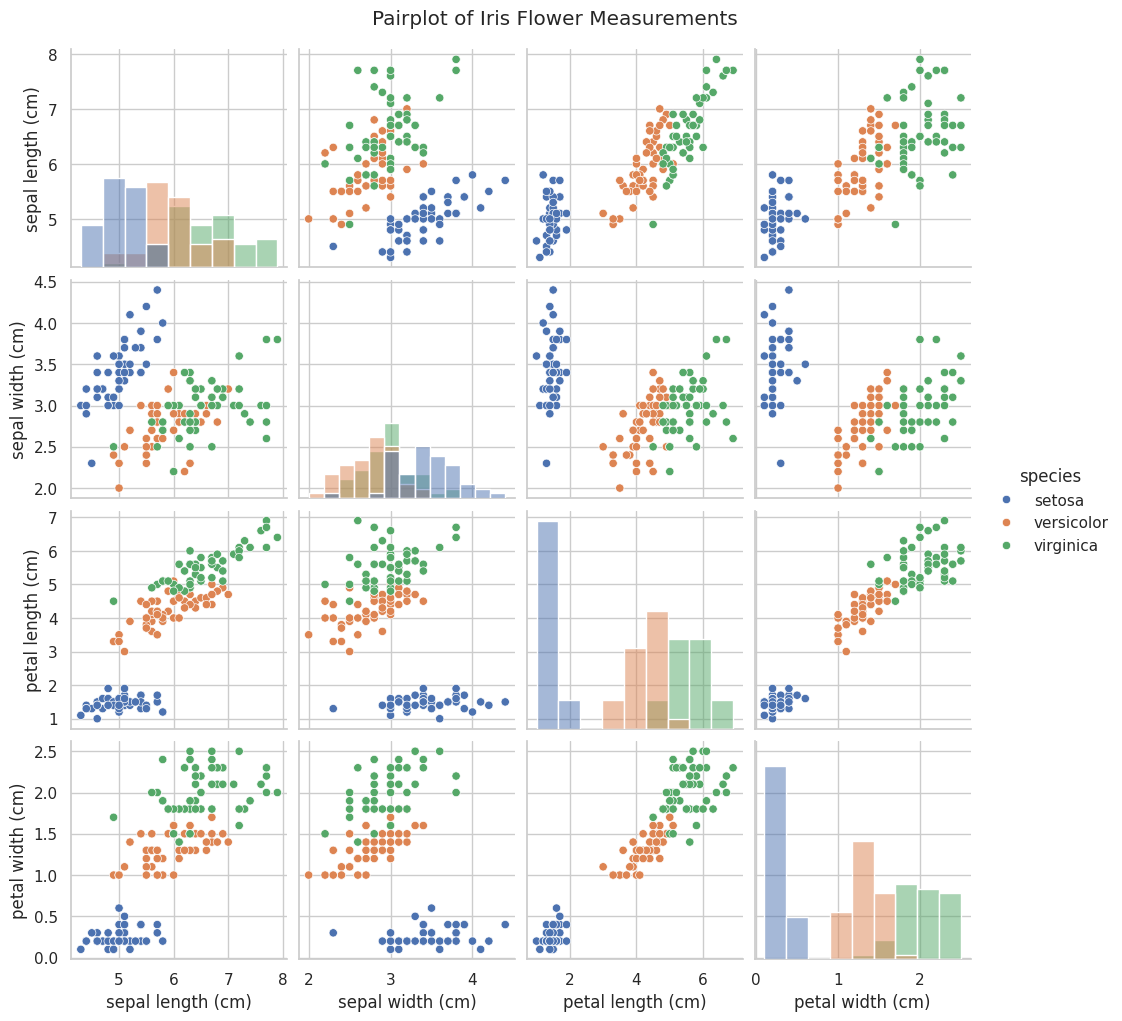

In [62]:
# Visualize relationships between measurements,
# using a different color for each species
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Iris Flower Measurements",
    y=1.02
)

plt.show()

### Pairplot Observations

The pairplot helps us compare the four measurements and identify patterns among the three species. Petal length and petal width appear particularly useful for distinguishing the species. Setosa is generally more clearly separated, while Versicolor and Virginica show more overlap.

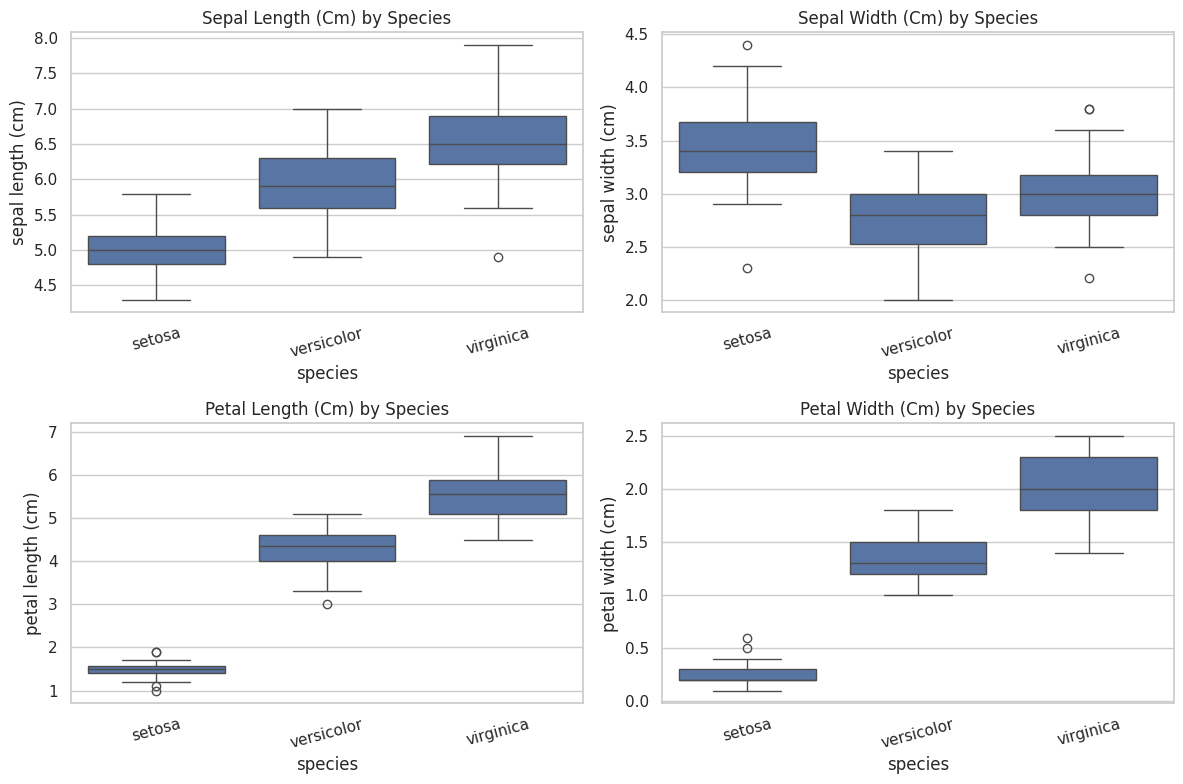

In [63]:
# List of measurement columns
features = iris.feature_names

# Create one box plot for each measurement
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature.title()} by Species")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


### Box Plot Observations

The box plots compare the distribution of each measurement across the three iris species. They help identify which features show the clearest differences and whether measurements overlap between species. These observations guide our choice of useful features for classification.
> Add blockquote



In [64]:
# Select the four measurement columns as input features
X = df[iris.feature_names]

# Select the species column as the target
y = df["species"]

print("Input features (X):", X.shape)
print("Target labels (y):", y.shape)

Input features (X): (150, 4)
Target labels (y): (150,)


In [65]:
# Use 80% of the data for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [66]:
# Define the classification models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train each model using the training data
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
K-Nearest Neighbors trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [67]:
# Evaluate each trained model on the test set
results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

# Display models ranked by test accuracy
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df[["Model", "Accuracy (%)"]])

,Model,Accuracy (%)
0,Logistic Regression,93.33
1,K-Nearest Neighbors,93.33
2,Decision Tree,93.33
3,Random Forest,90.00


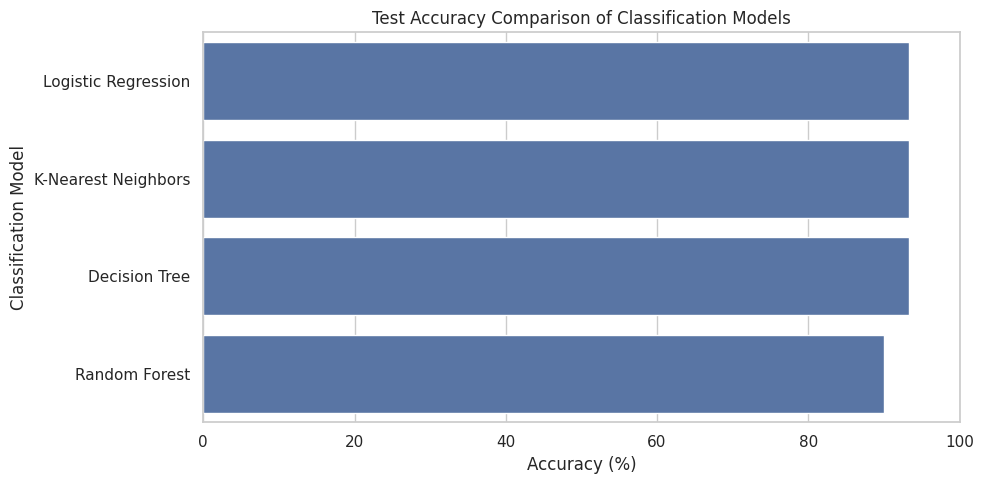

In [68]:
# Create a bar chart to compare test accuracy
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Accuracy (%)",
    y="Model"
)

plt.title("Test Accuracy Comparison of Classification Models")
plt.xlabel("Accuracy (%)")
plt.ylabel("Classification Model")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

Best model by test accuracy: Logistic Regression
Test accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



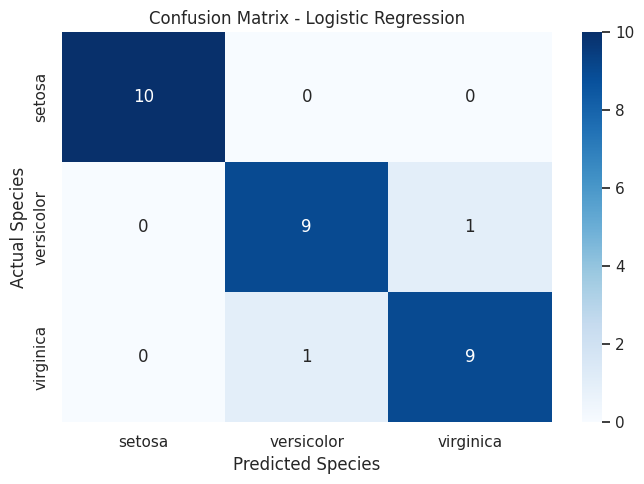

In [69]:
# Select the highest-accuracy model from our comparison
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

# Predict the test-set species using the selected model
y_pred = best_model.predict(X_test)

print("Best model by test accuracy:", best_model_name)
print(
    "Test accuracy:",
    f"{accuracy_score(y_test, y_pred) * 100:.2f}%"
)

# Display precision, recall, F1-score and support
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=iris.target_names,
        zero_division=0
    )
)

# Plot the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=iris.target_names
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

In [70]:
# Get the highest accuracy achieved in the comparison
highest_accuracy = results_df["Accuracy"].max()

# Identify all models that achieved that accuracy
top_models = results_df[
    results_df["Accuracy"] == highest_accuracy
]["Model"].tolist()

print("Model comparison summary:")
display(results_df[["Model", "Accuracy (%)"]])

print("\nBest-performing model(s):")
for model_name in top_models:
    print(
        f"- {model_name}: "
        f"{highest_accuracy * 100:.2f}% accuracy"
    )

print(
    "\nSelection basis: highest test accuracy "
    "on the same held-out test set."
)

Model comparison summary:


,Model,Accuracy (%)
0,Logistic Regression,93.33
1,K-Nearest Neighbors,93.33
2,Decision Tree,93.33
3,Random Forest,90.00



Best-performing model(s):
- Logistic Regression: 93.33% accuracy
- K-Nearest Neighbors: 93.33% accuracy
- Decision Tree: 93.33% accuracy

Selection basis: highest test accuracy on the same held-out test set.


### Model Selection and Justification

The four classification models were evaluated using the same held-out test set.

- **Logistic Regression:** 93.33% accuracy
- **K-Nearest Neighbors:** 93.33% accuracy
- **Decision Tree:** 93.33% accuracy
- **Random Forest:** 90.00% accuracy

**Best-performing models:** Logistic Regression, K-Nearest Neighbors, and Decision Tree.

**Justification:** Logistic Regression, K-Nearest Neighbors, and Decision Tree achieved the highest test accuracy of 93.33%. These three models are tied based on accuracy, so no single model can be declared the unique winner using this metric alone. Random Forest achieved 90.00% accuracy.

Precision, recall, F1-score, and the confusion matrices can be compared to understand the models' performance for each iris species.

In [71]:
# Example flower measurements in centimetres:
# sepal length, sepal width, petal length, petal width
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Predict the flower species
predicted_species = best_model.predict(new_flower)[0]

print("New flower measurements:")
display(new_flower)

print("Predicted flower species:", predicted_species)

New flower measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted flower species: setosa
